# 03 · Training the CNN (on a Kaggle GPU)
Training runs as a private Kaggle kernel, because it needs a GPU:

```bash
python kaggle/build_kernel.py train --user <kaggle-username>  # bundles src/ + splits/split.csv
kaggle kernels push -p kaggle/build/train                     # runs `python -m src.train` on a GPU
kaggle kernels output <user>/skin-lesion-triage-train -p models
```

The model was chosen by validation-only sweeps (see `results/sweep.json`): EfficientNet-B0
with label smoothing / stochastic depth, then FastViT-T12/S12, ConvNeXt V2-Femto,
EfficientNetV2-B0 and MobileNetV4-Hybrid-M with the same recipe. The winner (FastViT-T12) was
retrained at higher resolution with 15,316 extra ISIC 2019 training images (HAM10000
duplicates removed, SCC merged into akiec). Validation and test stay the HAM10000 splits.

Shared recipe (`src/train.py`): flips + 90° rotations + `RandomResizedCrop(0.7–1.0)` + light
colour jitter, weighted cross-entropy (`w = 1/sqrt(class_freq)`), head-only epochs then a full
fine-tune with AdamW (1e-4 backbone / 3e-4 head) on a one-cycle cosine schedule, mixed
precision. The checkpoint with the best **validation balanced accuracy** is kept. The exact
arguments of the deployed run are printed below.

**Why weighted CE over a weighted sampler?** The sampler would show the rare `df` images
dozens of times per epoch and overfit them; `1/sqrt(freq)` weights rebalance more gently.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

log = json.load(open("../models/train_log.json"))
h = pd.DataFrame(log["history"])
print("device:", log["device"], "| torch", log["torch"], "| best val balanced accuracy:", round(log["best_val_bacc"], 4))
print({k: v for k, v in log["args"].items() if k not in ("ham", "split", "fitz", "out", "isic19")},
      "| extra ISIC 2019 data:", bool(log["args"].get("isic19")))
h

device: cuda | torch 2.11.0+cu130 | best val balanced accuracy: 0.8322
{'head_epochs': 2, 'epochs': 30, 'batch_size': 64, 'limit': 0, 'workers': 4, 'backbone': 'fastvit_t12.apple_dist_in1k', 'label_smoothing': 0.1, 'drop_path': 0.2, 'img_size': 384} | extra ISIC 2019 data: True


,epoch,phase,train_loss,val_bacc
0,0,head,2.122240,0.142857
1,1,head,2.098526,0.142857
2,2,full,1.993695,0.206374
3,3,full,1.803079,0.507361
4,4,full,1.654729,0.684282
5,5,full,1.551002,0.657697
6,6,full,1.478700,0.768438
7,7,full,1.417892,0.754397
8,8,full,1.379189,0.697106
9,9,full,1.334814,0.796460


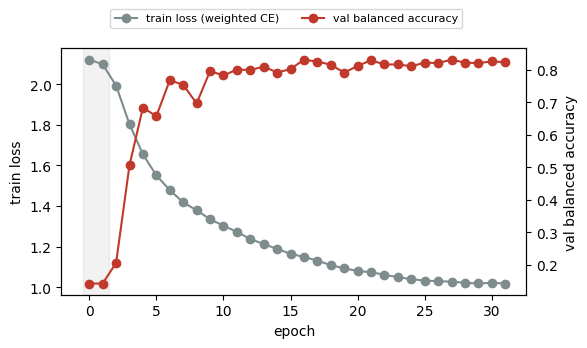

In [2]:
fig, ax1 = plt.subplots(figsize=(6, 3.2))
ax1.plot(h.epoch, h.train_loss, "o-", c="#7f8c8d", label="train loss (weighted CE)")
ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss")
ax2 = ax1.twinx()
ax2.plot(h.epoch, h.val_bacc, "o-", c="#c0392b", label="val balanced accuracy")
ax2.set_ylabel("val balanced accuracy")
ax1.axvspan(-0.5, (h.phase == "head").sum() - 0.5, color="gray", alpha=.1)
fig.legend(loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(.5, 1.02))
fig.savefig("../figures/training_curve.png", bbox_inches="tight")